In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q xgboost scikit-learn tensorflow matplotlib seaborn pandas numpy opencv-python-headless
print("✅ Paketler kuruldu.")

✅ Paketler kuruldu.


In [ ]:
import os, time, copy, warnings, gc
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

# Yöntem 1 ile AYNI 8 model
from tensorflow.keras.applications import (
    Xception, DenseNet121, InceptionV3, ResNet101V2, MobileNetV2,
    EfficientNetB0, VGG16, ResNet50V2
)
from tensorflow.keras.applications import (
    xception, densenet, inception_v3, resnet_v2, mobilenet_v2, efficientnet, vgg16
)

# ML kütüphaneleri (en az 5 model)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
print(f"✅ TensorFlow {tf.__version__} | GPU: {gpus[0].name if gpus else 'YOK — T4 seçin!'}")
print(f"✅ scikit-learn {__import__('sklearn').__version__} | XGBoost {__import__('xgboost').__version__}")

✅ TensorFlow 2.20.0 | GPU: /physical_device:GPU:0
✅ scikit-learn 1.6.1 | XGBoost 3.2.0


In [ ]:
# ── Veri yolları (Yöntem 1 ile aynı) ────────────────────────────────────────
SPLIT_DIR = "/content/drive/MyDrive/Colab Notebooks/Veri/paddydoc_split"
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "validation")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

# ── Yöntem 1'de kaydedilen ağırlıklar ───────────────────────────────────────
Y1_MODELS_DIR = "/content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem1/models"

# ── Yöntem 2 çıktıları ──────────────────────────────────────────────────────
OUTPUT_DIR   = "/content/drive/MyDrive/Colab Notebooks/Veri/DL_sonuclar/Yontem2"
FEATURES_DIR = os.path.join(OUTPUT_DIR, "features")
FIGURES_DIR  = os.path.join(OUTPUT_DIR, "figures")
RESULTS_DIR  = os.path.join(OUTPUT_DIR, "results")
for d in [FEATURES_DIR, FIGURES_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Sabitler ────────────────────────────────────────────────────────────────
IMG_SIZE = (256, 256)     # Yöntem 1 ile aynı
BATCH    = 32
N_FOLDS  = 5

CLASS_NAMES = sorted([d for d in os.listdir(TRAIN_DIR)
                      if os.path.isdir(os.path.join(TRAIN_DIR, d))])
NUM_CLASSES = len(CLASS_NAMES)

# Yöntem 1 ile AYNI modeller (ödev şartı: farklı olmasın)
MODEL_NAMES = ['Xception', 'DenseNet121', 'InceptionV3', 'ResNet101V2', 'MobileNetV2',
               'EfficientNetB0', 'VGG16', 'ResNet50V2']
MODEL_FILES = {n: os.path.join(Y1_MODELS_DIR, f"Yontem1_{n.lower()}_best.weights.h5")
               for n in MODEL_NAMES}

print(f"✅ Sınıf sayısı: {NUM_CLASSES}")
print(f"   {CLASS_NAMES}\n")
print("📁 Yöntem 1 ağırlık dosyaları:")
for n, fp in MODEL_FILES.items():
    ok = os.path.exists(fp)
    mb = os.path.getsize(fp)/1e6 if ok else 0
    print(f"  {'✅' if ok else '❌'} {n:<16} ({mb:.1f} MB)")

✅ Sınıf sayısı: 10
   ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']

📁 Yöntem 1 ağırlık dosyaları:
  ✅ Xception         (87.2 MB)
  ✅ DenseNet121      (31.0 MB)
  ✅ InceptionV3      (91.4 MB)
  ✅ ResNet101V2      (174.9 MB)
  ✅ MobileNetV2      (11.6 MB)
  ✅ EfficientNetB0   (19.0 MB)
  ✅ VGG16            (59.9 MB)
  ✅ ResNet50V2       (98.1 MB)


In [ ]:
def load_images_from_dir(directory, img_size=(256, 256)):
    images, labels = [], []
    for idx, cls in enumerate(CLASS_NAMES):
        cls_path = os.path.join(directory, cls)
        if not os.path.isdir(cls_path):
            print(f"  ⚠️  klasör yok: {cls_path}"); continue
        for fname in sorted(os.listdir(cls_path)):
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                continue
            img = cv2.imread(os.path.join(cls_path, fname))
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, img_size)
            images.append(img); labels.append(idx)
    return np.array(images, dtype=np.uint8), np.array(labels, dtype=np.int32)

print("⏳ Görüntüler yükleniyor...")
t0 = time.time()
X_tr, y_tr = load_images_from_dir(TRAIN_DIR, IMG_SIZE)
X_va, y_va = load_images_from_dir(VAL_DIR,   IMG_SIZE)
X_te, y_te = load_images_from_dir(TEST_DIR,  IMG_SIZE)

X_all = np.concatenate([X_tr, X_va, X_te], axis=0)
y_all = np.concatenate([y_tr, y_va, y_te], axis=0)
shuf = np.random.RandomState(SEED).permutation(len(X_all))
X_all, y_all = X_all[shuf], y_all[shuf]

print(f"✅ Yükleme tamam ({time.time()-t0:.1f} sn) | toplam {len(X_all)} görüntü | boyut {X_all.shape[1:]}")
for i, cls in enumerate(CLASS_NAMES):
    print(f"   {cls:<26} {np.sum(y_all==i):>5}")

⏳ Görüntüler yükleniyor...
✅ Yükleme tamam (519.5 sn) | toplam 3200 görüntü | boyut (256, 256, 3)
   bacterial_leaf_blight        320
   bacterial_leaf_streak        320
   bacterial_panicle_blight     320
   blast                        320
   brown_spot                   320
   dead_heart                   320
   downy_mildew                 320
   hispa                        320
   normal                       320
   tungro                       320


In [ ]:
BACKBONES = {'Xception':Xception,'DenseNet121':DenseNet121,'InceptionV3':InceptionV3,
             'ResNet101V2':ResNet101V2,'MobileNetV2':MobileNetV2,'EfficientNetB0':EfficientNetB0,
             'VGG16':VGG16,'ResNet50V2':ResNet50V2}
PREPROCESS = {'Xception':xception.preprocess_input,'DenseNet121':densenet.preprocess_input,
              'InceptionV3':inception_v3.preprocess_input,'ResNet101V2':resnet_v2.preprocess_input,
              'MobileNetV2':mobilenet_v2.preprocess_input,'EfficientNetB0':efficientnet.preprocess_input,
              'VGG16':vgg16.preprocess_input,'ResNet50V2':resnet_v2.preprocess_input}

def rebuild_model(name, num_classes=None, img_size=None):
    """Yöntem 1 ile BİREBİR aynı mimari."""
    num_classes = num_classes or NUM_CLASSES
    img_size = img_size or IMG_SIZE
    input_shape = (*img_size, 3)
    inputs = keras.Input(shape=input_shape)
    x = layers.Lambda(PREPROCESS[name], name='preprocess')(inputs)
    base = BACKBONES[name](include_top=False, weights='imagenet', input_shape=input_shape)
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax', name='predictions')(x)
    return Model(inputs, out, name=name)

feature_extractors = {}
print("⏳ Modeller kuruluyor, ağırlıklar yükleniyor...\n")
for name in MODEL_NAMES:
    full = rebuild_model(name)
    fpath = MODEL_FILES[name]
    if os.path.exists(fpath):
        try:
            full.load_weights(fpath)
            status = "✅ eğitilmiş ağırlıklar"
        except Exception as e:
            status = f"⚠️  imagenet (yükleme hatası)"
    else:
        status = "⚠️  imagenet (ckpt bulunamadı)"
    extractor = keras.Model(full.input, full.get_layer('gap').output, name=f"ext_{name}")
    feature_extractors[name] = extractor
    print(f"  {name:<16} feat_dim={extractor.output_shape[-1]:>5} | {status}")
    del full; gc.collect()

print(f"\n✅ {len(feature_extractors)} feature extractor hazır.")

⏳ Modeller kuruluyor, ağırlıklar yükleniyor...

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
  Xception         feat_dim= 2048 | ✅ eğitilmiş ağırlıklar
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
  DenseNet121      feat_dim= 1024 | ✅ eğitilmiş ağırlıklar
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
  InceptionV3      feat_dim= 2048 | ✅ eğitilmiş ağırlıklar
171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
  ResNet101V2      feat_dim= 2048 | ✅ eğitilmiş ağırlıklar
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
  MobileNetV2      feat_dim= 1280 | ✅ eğitilmiş ağırlıklar
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
  EfficientNetB0   feat_dim= 1280 | ✅ eğitilmiş ağırlıklar
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  VGG16            feat_dim=  512 | ✅ eğitilmiş ağırlıklar
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
  ResNet50V2       feat_dim= 2048 | ✅ eğitilmiş ağırlıklar

✅ 8 feature extractor hazır.


In [ ]:
def extract_features_batched(extractor, X_raw, batch_size=32):
    feats, n = [], len(X_raw)
    for s in range(0, n, batch_size):
        e = min(s+batch_size, n)
        batch = X_raw[s:e].astype(np.float32)     # HAM [0,255] — preprocess model içinde
        feats.append(extractor.predict(batch, verbose=0))
        print(f"    {e}/{n}", end="\r")
    print(f"    {n}/{n} ✓        ")
    return np.concatenate(feats, axis=0)

print("="*60)
print("  Özellik Çıkarımı (8 DL modeli)")
print("="*60)
for name in MODEL_NAMES:
    save_path = os.path.join(FEATURES_DIR, f"Yontem2_features_{name.lower()}.npy")
    if os.path.exists(save_path):
        print(f"  ⏭️  {name:<16} zaten var → {np.load(save_path).shape}")
        continue
    print(f"\n  [{name}] çıkarılıyor...")
    t0 = time.time()
    f = extract_features_batched(feature_extractors[name], X_all, BATCH)
    np.save(save_path, f)
    print(f"  ✅ {name:<16} shape={f.shape} | {time.time()-t0:.1f}s | {os.path.getsize(save_path)/1e6:.1f} MB")

np.save(os.path.join(FEATURES_DIR, "Yontem2_labels.npy"), y_all)
print("\n✅ Tüm özellikler ve etiketler kaydedildi.")

  Özellik Çıkarımı (8 DL modeli)
  ⏭️  Xception         zaten var → (3200, 2048)
  ⏭️  DenseNet121      zaten var → (3200, 1024)
  ⏭️  InceptionV3      zaten var → (3200, 2048)
  ⏭️  ResNet101V2      zaten var → (3200, 2048)
  ⏭️  MobileNetV2      zaten var → (3200, 1280)
  ⏭️  EfficientNetB0   zaten var → (3200, 1280)
  ⏭️  VGG16            zaten var → (3200, 512)
  ⏭️  ResNet50V2       zaten var → (3200, 2048)

✅ Tüm özellikler ve etiketler kaydedildi.


In [ ]:
print("📂 Özellik dosyaları yükleniyor...\n")
features_dict = {}
y_cv = np.load(os.path.join(FEATURES_DIR, "Yontem2_labels.npy"))

for name in MODEL_NAMES:
    fp = os.path.join(FEATURES_DIR, f"Yontem2_features_{name.lower()}.npy")
    if not os.path.exists(fp):
        print(f"  ⚠️  {name}: dosya yok"); continue
    features_dict[name] = np.load(fp)
    print(f"  ✅ {name:<16} → shape {features_dict[name].shape}")

print(f"\n  Etiketler → {y_cv.shape}")
for i, cls in enumerate(CLASS_NAMES):
    print(f"   {cls:<26} {np.sum(y_cv==i):>5}")

📂 Özellik dosyaları yükleniyor...

  ✅ Xception         → shape (3200, 2048)
  ✅ DenseNet121      → shape (3200, 1024)
  ✅ InceptionV3      → shape (3200, 2048)
  ✅ ResNet101V2      → shape (3200, 2048)
  ✅ MobileNetV2      → shape (3200, 1280)
  ✅ EfficientNetB0   → shape (3200, 1280)
  ✅ VGG16            → shape (3200, 512)
  ✅ ResNet50V2       → shape (3200, 2048)

  Etiketler → (3200,)
   bacterial_leaf_blight        320
   bacterial_leaf_streak        320
   bacterial_panicle_blight     320
   blast                        320
   brown_spot                   320
   dead_heart                   320
   downy_mildew                 320
   hispa                        320
   normal                       320
   tungro                       320


In [ ]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

ML_MODELS = {
    "SVM": SVC(kernel='rbf', C=10, gamma='scale', random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                             random_state=SEED, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1),
    "Logistic Regression": LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000,
                                              class_weight='balanced', random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, subsample=0.8,
                             eval_metric='mlogloss', random_state=SEED, n_jobs=-1, verbosity=0),
}
PCA_THRESHOLD = 1500

print(f"✅ {N_FOLDS}-Fold CV | ML modelleri: {list(ML_MODELS.keys())}")
for name, arr in features_dict.items():
    print(f"   {name:<16} boyut={arr.shape[1]:>5} → PCA={'EVET' if arr.shape[1] > PCA_THRESHOLD else 'hayır'}")

✅ 5-Fold CV | ML modelleri: ['SVM', 'Random Forest', 'KNN', 'Logistic Regression', 'XGBoost']
   Xception         boyut= 2048 → PCA=EVET
   DenseNet121      boyut= 1024 → PCA=hayır
   InceptionV3      boyut= 2048 → PCA=EVET
   ResNet101V2      boyut= 2048 → PCA=EVET
   MobileNetV2      boyut= 1280 → PCA=hayır
   EfficientNetB0   boyut= 1280 → PCA=hayır
   VGG16            boyut=  512 → PCA=hayır
   ResNet50V2       boyut= 2048 → PCA=EVET


In [ ]:
from tensorflow.keras.applications import (
    Xception, DenseNet121, InceptionV3, ResNet101V2, MobileNetV2,
    EfficientNetB0, VGG16, ResNet50V2
)
_BACKBONES = {'Xception':Xception,'DenseNet121':DenseNet121,'InceptionV3':InceptionV3,
              'ResNet101V2':ResNet101V2,'MobileNetV2':MobileNetV2,'EfficientNetB0':EfficientNetB0,
              'VGG16':VGG16,'ResNet50V2':ResNet50V2}
_MODEL_NAMES = list(_BACKBONES.keys())

print("="*70); print("  ÖZELLİK ÇIKARIM KATMANLARI"); print("="*70)
rows = []
for name in _MODEL_NAMES:
    bb = _BACKBONES[name](include_top=False, weights=None, input_shape=(256,256,3))
    last_conv = bb.layers[-1]
    rows.append({
        "DL Modeli"      : name,
        "Backbone"       : bb.name,
        "Son Konv Katman": last_conv.name,
        "Konv Çıkış"     : str(tuple(bb.output_shape[1:])),
        "Çıkarım Katmanı": "GlobalAveragePooling2D",
        "Özellik Boyutu" : bb.output_shape[-1],
    })
    del bb
    import gc; gc.collect()
    import tensorflow as tf; tf.keras.backend.clear_session()

import pandas as pd
layers_df = pd.DataFrame(rows)
print(layers_df.to_string(index=False))

  ÖZELLİK ÇIKARIM KATMANLARI
     DL Modeli             Backbone      Son Konv Katman   Konv Çıkış        Çıkarım Katmanı  Özellik Boyutu
      Xception             xception block14_sepconv2_act (8, 8, 2048) GlobalAveragePooling2D            2048
   DenseNet121          densenet121                 relu (8, 8, 1024) GlobalAveragePooling2D            1024
   InceptionV3         inception_v3              mixed10 (6, 6, 2048) GlobalAveragePooling2D            2048
   ResNet101V2          resnet101v2            post_relu (8, 8, 2048) GlobalAveragePooling2D            2048
   MobileNetV2 mobilenetv2_1.00_256             out_relu (8, 8, 1280) GlobalAveragePooling2D            1280
EfficientNetB0       efficientnetb0       top_activation (8, 8, 1280) GlobalAveragePooling2D            1280
         VGG16                vgg16          block5_pool  (8, 8, 512) GlobalAveragePooling2D             512
    ResNet50V2           resnet50v2            post_relu (8, 8, 2048) GlobalAveragePooling2D       

In [ ]:
all_cv_results = []
print("="*70)
print(f"  5-Fold CV — {len(features_dict)} DL × {len(ML_MODELS)} ML = {len(features_dict)*len(ML_MODELS)} kombinasyon")
print("="*70)

for dl_name in MODEL_NAMES:
    if dl_name not in features_dict:
        continue
    X_feat, y = features_dict[dl_name], y_cv
    use_pca = X_feat.shape[1] > PCA_THRESHOLD
    print(f"\n{'─'*70}\n  DL: {dl_name:<16} boyut={X_feat.shape[1]} PCA={'EVET' if use_pca else 'hayır'}\n{'─'*70}")

    for ml_name, ml_clf in ML_MODELS.items():
        accs, precs, recs, f1s = [], [], [], []
        t_start = time.time()
        for tr, te in skf.split(X_feat, y):
            Xtr, Xte = X_feat[tr], X_feat[te]
            ytr, yte = y[tr], y[te]
            sc = StandardScaler(); Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
            if use_pca:
                pca = PCA(n_components=0.95, random_state=SEED)
                Xtr = pca.fit_transform(Xtr); Xte = pca.transform(Xte)
            clf = copy.deepcopy(ml_clf); clf.fit(Xtr, ytr); yp = clf.predict(Xte)
            accs.append(accuracy_score(yte, yp))
            precs.append(precision_score(yte, yp, average='macro', zero_division=0))
            recs.append(recall_score(yte, yp, average='macro', zero_division=0))
            f1s.append(f1_score(yte, yp, average='macro', zero_division=0))
        elapsed = time.time() - t_start
        all_cv_results.append({
            "DL Modeli": dl_name, "ML Modeli": ml_name,
            "Accuracy": round(np.mean(accs),4), "Acc Std": round(np.std(accs),4),
            "Precision": round(np.mean(precs),4), "Recall": round(np.mean(recs),4),
            "F1-score": round(np.mean(f1s),4), "F1 Std": round(np.std(f1s),4),
            "Train+Test Süresi (sn)": round(elapsed,1)})
        print(f"  {ml_name:<22} Acc={np.mean(accs):.4f} F1={np.mean(f1s):.4f}±{np.std(f1s):.4f}  {elapsed:.1f}s")

print("\n" + "═"*70 + "\n  ✅ 5-Fold CV tamamlandı.\n" + "═"*70)

  5-Fold CV — 8 DL × 5 ML = 40 kombinasyon

──────────────────────────────────────────────────────────────────────
  DL: Xception         boyut=2048 PCA=EVET
──────────────────────────────────────────────────────────────────────
  SVM                    Acc=0.8369 F1=0.8364±0.0162  27.6s
  Random Forest          Acc=0.7366 F1=0.7357±0.0101  21.6s
  KNN                    Acc=0.7534 F1=0.7523±0.0172  10.3s
  Logistic Regression    Acc=0.7584 F1=0.7580±0.0130  22.5s
  XGBoost                Acc=0.7403 F1=0.7393±0.0146  560.7s

──────────────────────────────────────────────────────────────────────
  DL: DenseNet121      boyut=1024 PCA=hayır
──────────────────────────────────────────────────────────────────────
  SVM                    Acc=0.8975 F1=0.8973±0.0134  24.8s
  Random Forest          Acc=0.8125 F1=0.8105±0.0138  12.5s
  KNN                    Acc=0.8356 F1=0.8338±0.0095  0.4s
  Logistic Regression    Acc=0.8175 F1=0.8169±0.0156  9.6s
  XGBoost                Acc=0.8106 F1=0.8097

═══════════════════════════════════════════════════════════════════════════════════════════════
  📊 KARŞILAŞTIRMA TABLOSU — 5-Fold CV Ortalaması
═══════════════════════════════════════════════════════════════════════════════════════════════
         DL Modeli            ML Modeli  Accuracy  Precision  Recall  F1-score  F1 Std  Train+Test Süresi (sn)
1      DenseNet121                  SVM    0.8975     0.8989  0.8975    0.8973  0.0134                    24.8
2   EfficientNetB0                  SVM    0.8738     0.8756  0.8738    0.8736  0.0141                    29.8
3      MobileNetV2                  SVM    0.8566     0.8578  0.8566    0.8558  0.0121                    34.0
4         Xception                  SVM    0.8369     0.8385  0.8369    0.8364  0.0162                    27.6
5      DenseNet121                  KNN    0.8356     0.8377  0.8356    0.8338  0.0095                     0.4
6   EfficientNetB0  Logistic Regression    0.8281     0.8298  0.8281    0.8278  0.0188       

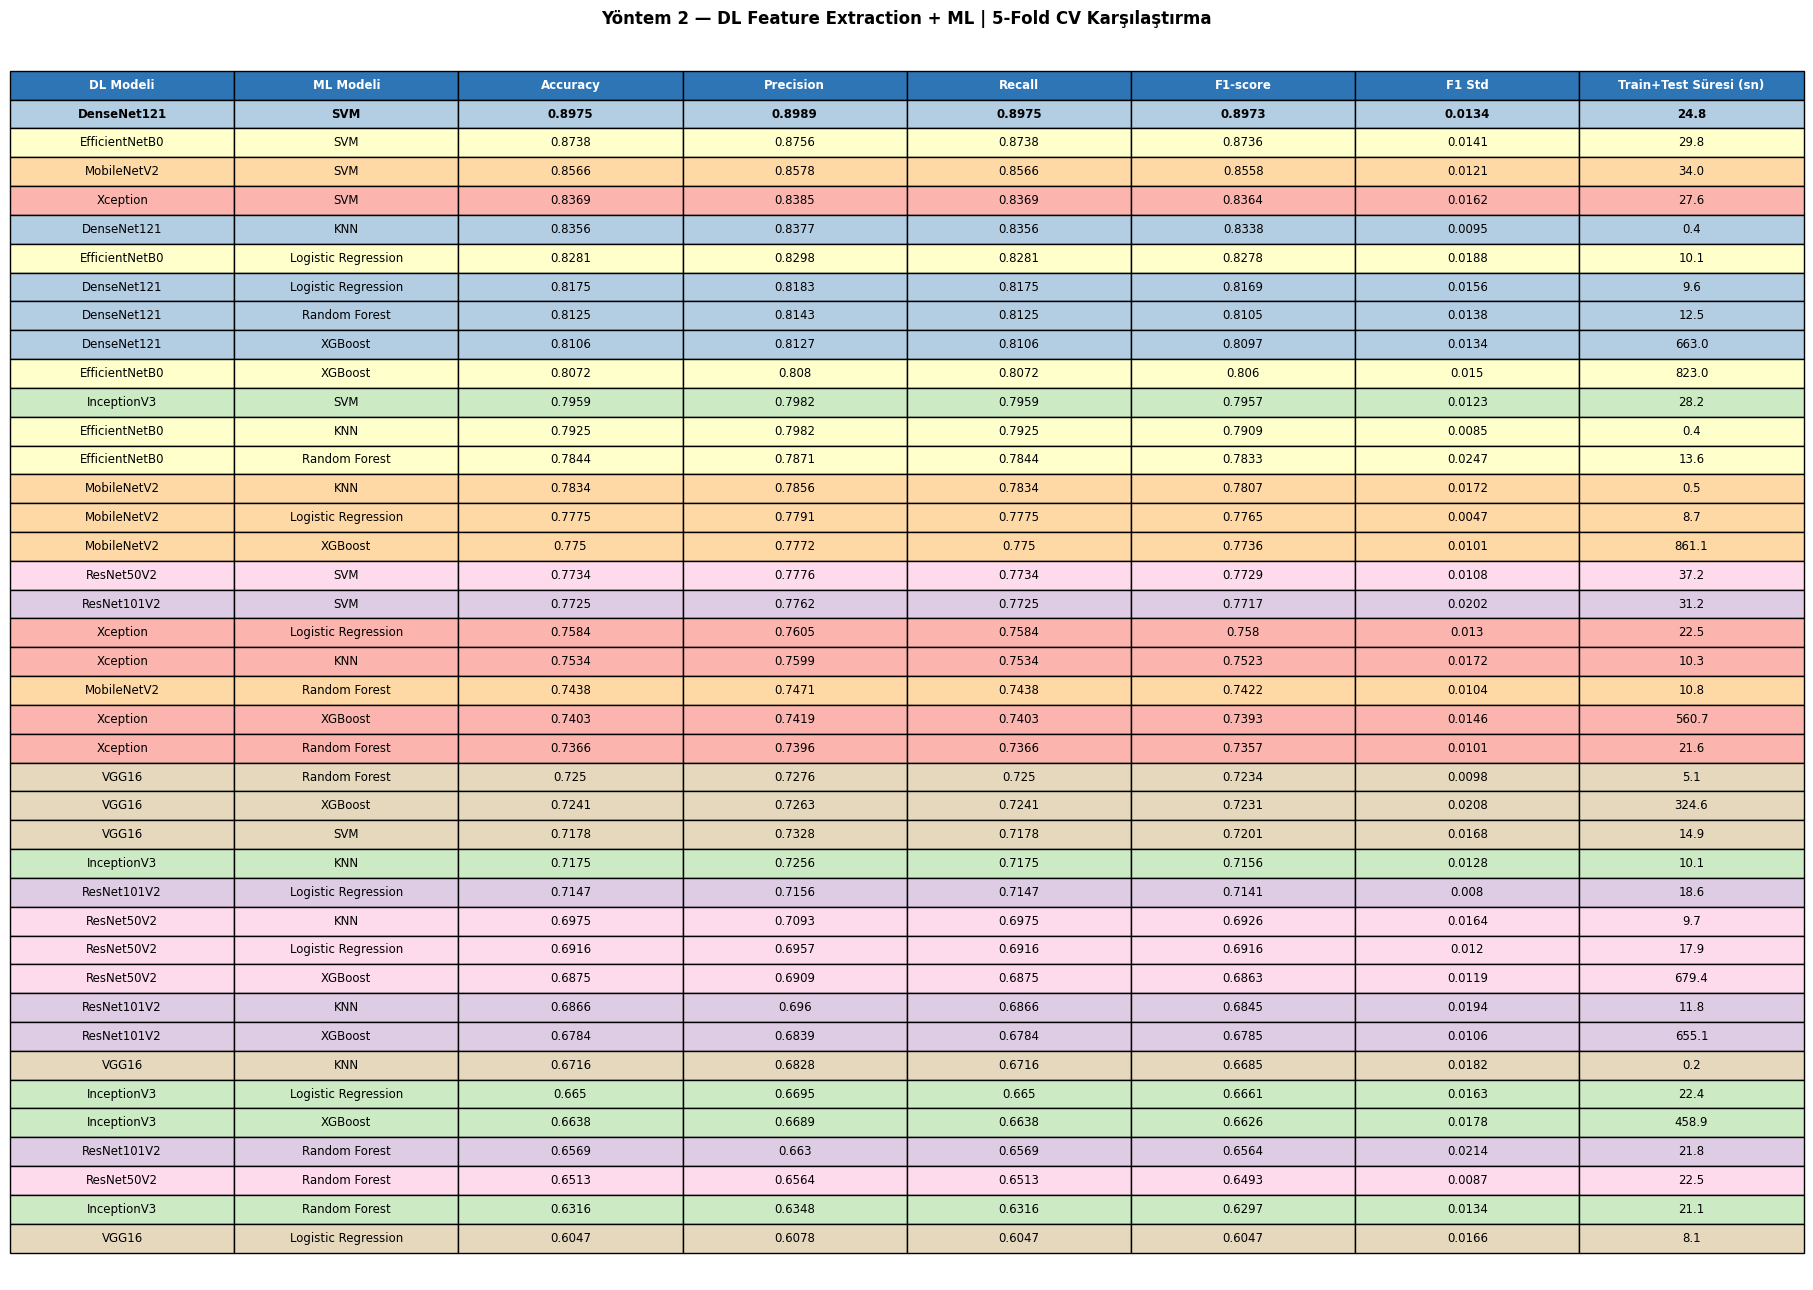

In [ ]:
results_df = pd.DataFrame(all_cv_results).sort_values('F1-score', ascending=False).reset_index(drop=True)
results_df.index += 1
best_row = results_df.iloc[0]
best_dl_name, best_ml_name, best_f1 = best_row['DL Modeli'], best_row['ML Modeli'], best_row['F1-score']
results_df.to_csv(os.path.join(RESULTS_DIR, "Yontem2_karsilastirma.csv"))

disp = ['DL Modeli','ML Modeli','Accuracy','Precision','Recall','F1-score','F1 Std','Train+Test Süresi (sn)']
print("═"*95)
print("  📊 KARŞILAŞTIRMA TABLOSU — 5-Fold CV Ortalaması")
print("═"*95)
print(results_df[disp].to_string())
print(f"\n🏆 En İyi: {best_dl_name} + {best_ml_name} (F1={best_f1:.4f})")

row_colors = {dl: plt.get_cmap('Pastel1')(i % 9) for i, dl in enumerate(MODEL_NAMES)}
fig, ax = plt.subplots(figsize=(18, 13)); ax.axis('off')
tbl = ax.table(cellText=results_df[disp].values, colLabels=disp, loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1.1, 1.4)
for j in range(len(disp)):
    tbl[(0,j)].set_facecolor('#2E75B6'); tbl[(0,j)].set_text_props(color='white', fontweight='bold')
for i, dl in enumerate(results_df['DL Modeli'].tolist()):
    for j in range(len(disp)):
        tbl[(i+1,j)].set_facecolor(row_colors.get(dl, '#FFFFFF'))
for j in range(len(disp)):
    tbl[(1,j)].set_text_props(fontweight='bold')
plt.title("Yöntem 2 — DL Feature Extraction + ML | 5-Fold CV Karşılaştırma", fontsize=12, fontweight='bold', pad=14)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "Yontem2_karsilastirma_tablosu.png"), dpi=150, bbox_inches='tight'); plt.show()

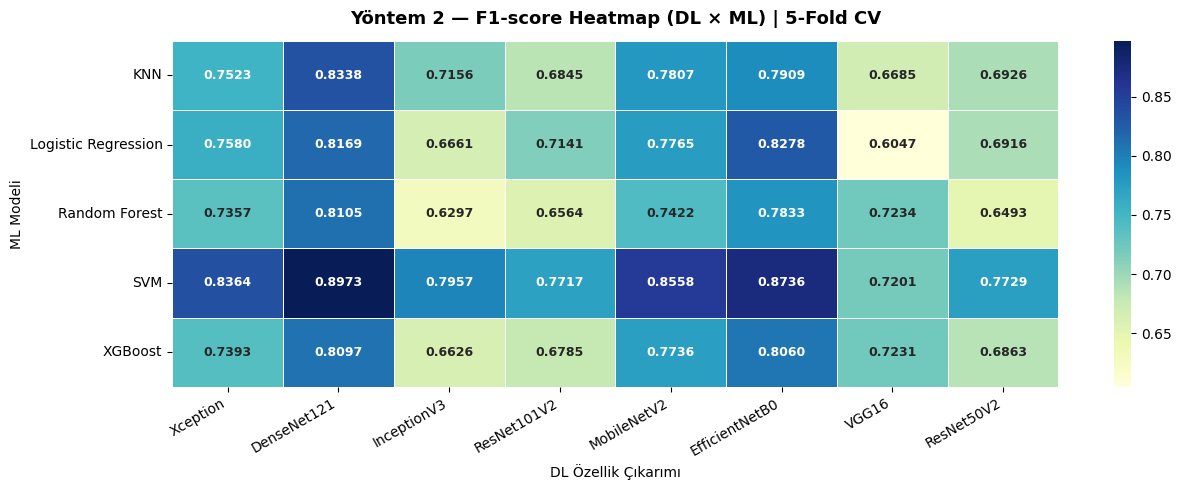

In [ ]:
pivot_f1 = results_df.pivot(index='ML Modeli', columns='DL Modeli', values='F1-score')
pivot_f1 = pivot_f1.reindex(columns=[c for c in MODEL_NAMES if c in pivot_f1.columns])

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pivot_f1, annot=True, fmt='.4f', cmap='YlGnBu', linewidths=0.5, linecolor='white',
            ax=ax, annot_kws={'size':9,'weight':'bold'})
ax.set_title("Yöntem 2 — F1-score Heatmap (DL × ML) | 5-Fold CV", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('DL Özellik Çıkarımı'); ax.set_ylabel('ML Modeli')
plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "Yontem2_f1_heatmap.png"), dpi=150, bbox_inches='tight'); plt.show()

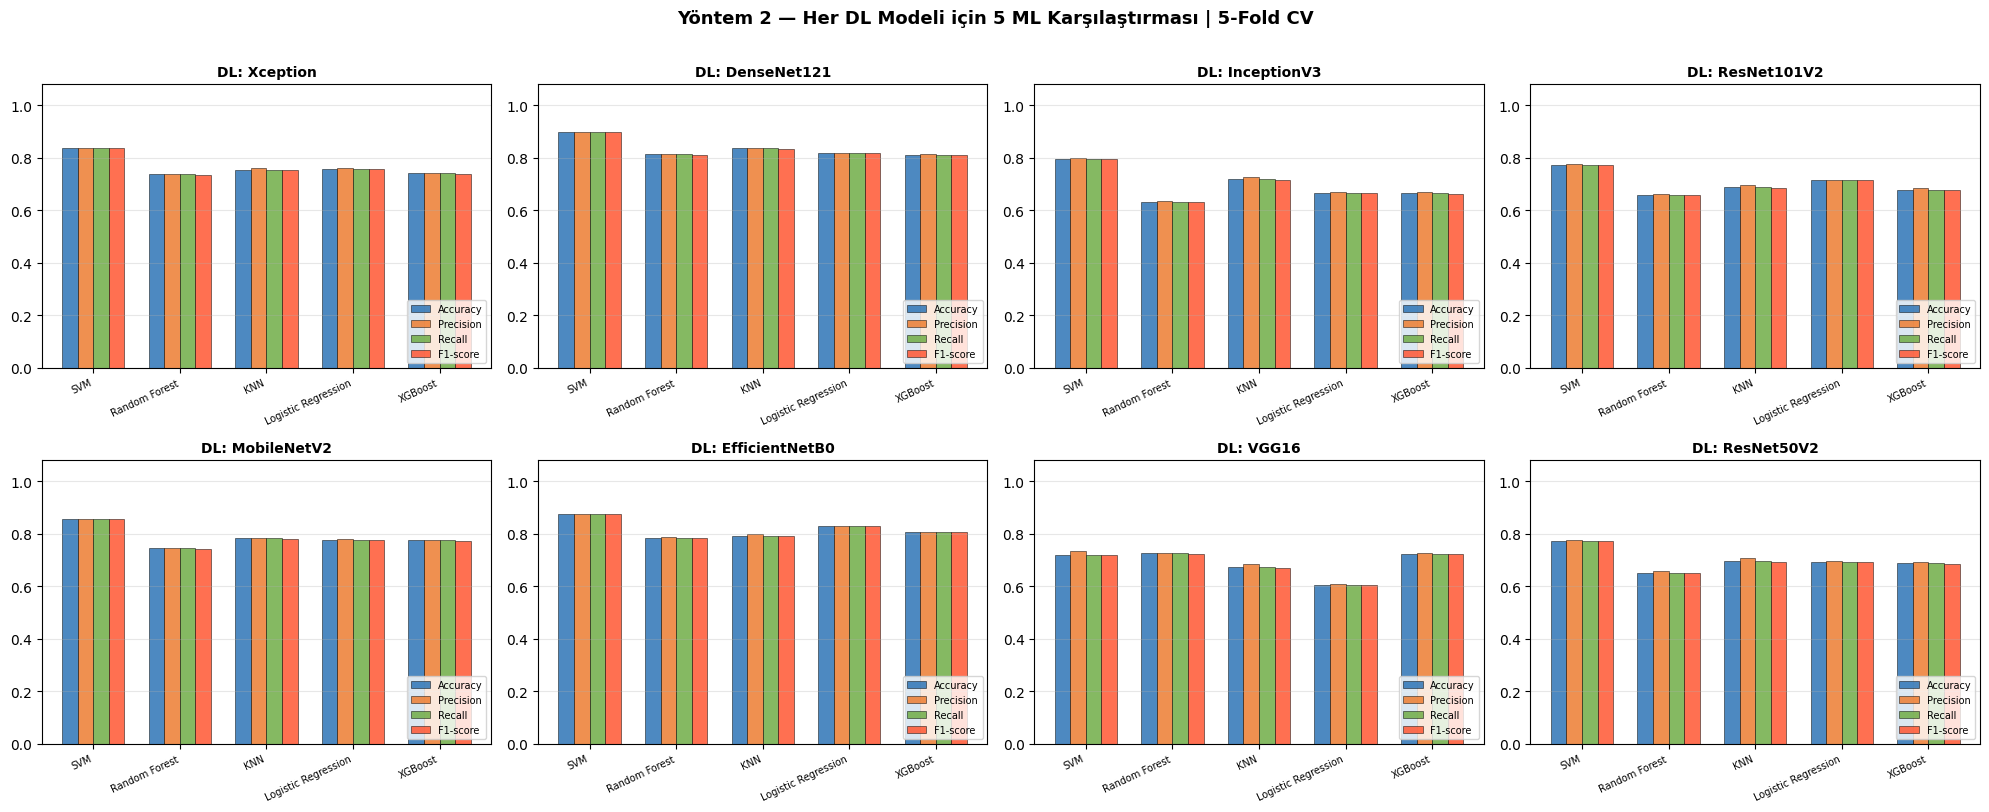

In [ ]:
import math
ml_keys = list(ML_MODELS.keys()); n_ml = len(ml_keys)
metrics = ['Accuracy','Precision','Recall','F1-score']; bar_w = 0.18
palette = ['#2E75B6','#ED7D31','#70AD47','#FF5733']
n_dl = len(MODEL_NAMES); ncol = 4; nrow = math.ceil(n_dl/ncol)

fig, axes = plt.subplots(nrow, ncol, figsize=(5*ncol, 4*nrow))
axes = np.array(axes).reshape(-1)
for i, dl_name in enumerate(MODEL_NAMES):
    ax = axes[i]
    if dl_name not in results_df['DL Modeli'].values:
        ax.set_visible(False); continue
    sub = results_df[results_df['DL Modeli']==dl_name].set_index('ML Modeli')
    x = np.arange(n_ml)
    for j,(metric,color) in enumerate(zip(metrics,palette)):
        vals = [sub.loc[ml,metric] if ml in sub.index else 0 for ml in ml_keys]
        ax.bar(x+j*bar_w, vals, bar_w, label=metric, color=color, alpha=0.85, edgecolor='black', linewidth=0.4)
    ax.set_title(f"DL: {dl_name}", fontsize=10, fontweight='bold')
    ax.set_xticks(x+bar_w*1.5); ax.set_xticklabels(ml_keys, rotation=25, ha='right', fontsize=7)
    ax.set_ylim(0,1.08); ax.legend(fontsize=7, loc='lower right'); ax.grid(axis='y', alpha=0.3)
for k in range(n_dl, len(axes)):
    axes[k].set_visible(False)
plt.suptitle("Yöntem 2 — Her DL Modeli için 5 ML Karşılaştırması | 5-Fold CV", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "Yontem2_grouped_bar.png"), dpi=150, bbox_inches='tight'); plt.show()

🏆 En İyi Kombinasyon: DenseNet121 + SVM (F1=0.8973)

⏳ cross_val_predict (5 fold)...
✅ 7.2 sn

───────────────────────────────────────────────────────
  Classification Report — DenseNet121 + SVM
───────────────────────────────────────────────────────
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.87      0.93      0.90       320
   bacterial_leaf_streak       0.94      0.96      0.95       320
bacterial_panicle_blight       0.94      0.98      0.96       320
                   blast       0.87      0.88      0.88       320
              brown_spot       0.86      0.83      0.85       320
              dead_heart       0.97      0.91      0.94       320
            downy_mildew       0.86      0.92      0.89       320
                   hispa       0.86      0.82      0.84       320
                  normal       0.91      0.88      0.89       320
                  tungro       0.89      0.86      0.87       320

                accur

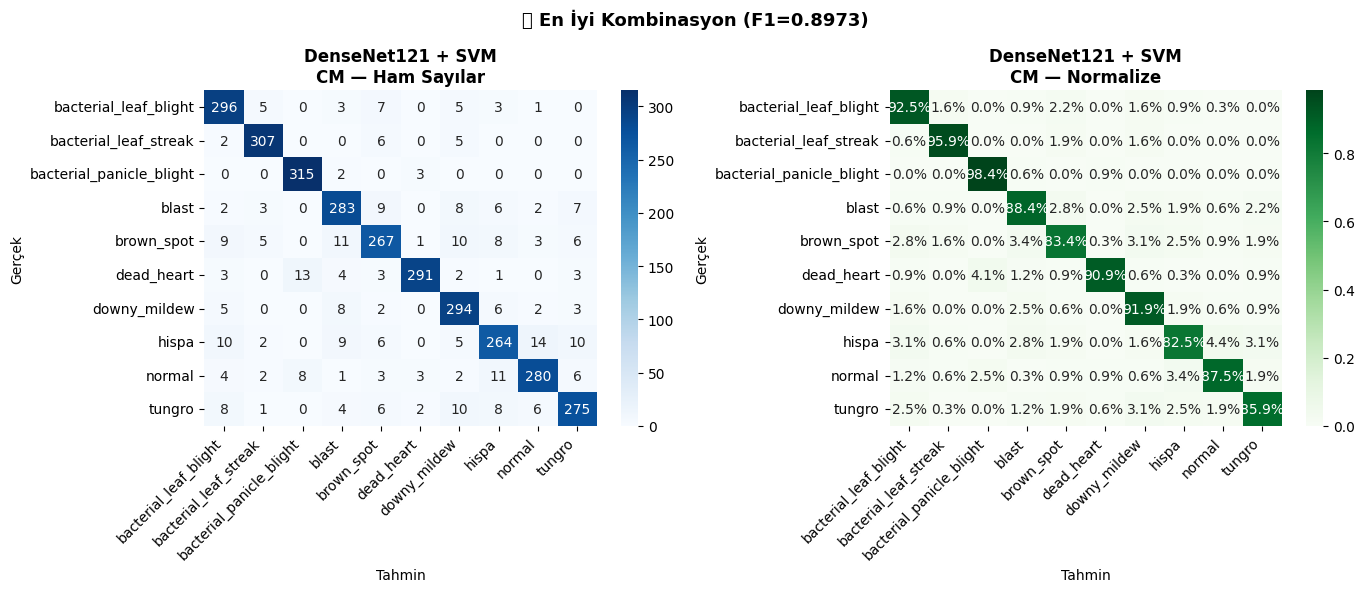

In [ ]:
print(f"🏆 En İyi Kombinasyon: {best_dl_name} + {best_ml_name} (F1={best_f1:.4f})\n")

X_best, y_best = features_dict[best_dl_name], y_cv
sc = StandardScaler(); X_best_s = sc.fit_transform(X_best)
if X_best.shape[1] > PCA_THRESHOLD:
    X_best_s = PCA(n_components=0.95, random_state=SEED).fit_transform(X_best_s)
    print(f"   PCA sonrası boyut: {X_best_s.shape[1]}")

clf_best = copy.deepcopy(ML_MODELS[best_ml_name])
print(f"⏳ cross_val_predict ({N_FOLDS} fold)...")
t0 = time.time()
y_pred_all = cross_val_predict(clf_best, X_best_s, y_best, cv=skf, n_jobs=-1)
print(f"✅ {time.time()-t0:.1f} sn\n")

print("─"*55)
print(f"  Classification Report — {best_dl_name} + {best_ml_name}")
print("─"*55)
print(classification_report(y_best, y_pred_all, target_names=CLASS_NAMES, zero_division=0))

cm_abs = confusion_matrix(y_best, y_pred_all)
cm_norm = cm_abs.astype('float') / cm_abs.sum(axis=1)[:, np.newaxis]
fig, axes = plt.subplots(1, 2, figsize=(2*max(7, NUM_CLASSES*0.65), max(6, NUM_CLASSES*0.6)))
sns.heatmap(cm_abs, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"{best_dl_name} + {best_ml_name}\nCM — Ham Sayılar", fontweight='bold')
axes[0].set_xlabel('Tahmin'); axes[0].set_ylabel('Gerçek')
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title(f"{best_dl_name} + {best_ml_name}\nCM — Normalize", fontweight='bold')
axes[1].set_xlabel('Tahmin'); axes[1].set_ylabel('Gerçek')
for a in axes:
    a.set_xticklabels(a.get_xticklabels(), rotation=45, ha='right'); a.set_yticklabels(a.get_yticklabels(), rotation=0)
plt.suptitle(f"🏆 En İyi Kombinasyon (F1={best_f1:.4f})", fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "Yontem2_enIyi_cm.png"), dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
print("="*65); print("  YÖNTEM 2 — TAMAMLANDI ✅"); print("="*65)
print("\n📁 Özellik dosyaları:")
for f in sorted(os.listdir(FEATURES_DIR)):
    print(f"  ✅ {f}  ({os.path.getsize(os.path.join(FEATURES_DIR,f))/1e6:.1f} MB)")
print("\n📊 Grafikler:")
for f in sorted(os.listdir(FIGURES_DIR)): print(f"  📊 {f}")
print("\n📋 Sonuçlar:")
for f in sorted(os.listdir(RESULTS_DIR)): print(f"  📋 {f}")

print("\n" + "="*65); print("  📊 EN İYİ 5 KOMBİNASYON:"); print("="*65)
disp = ['DL Modeli','ML Modeli','Accuracy','Precision','Recall','F1-score','Train+Test Süresi (sn)']
print(results_df[disp].head(5).to_string())
print(f"\n🏆 En İyi: {best_dl_name} + {best_ml_name} (F1={best_f1:.4f})")
print(f"⏱️  Tüm kombinasyonların toplam CV süresi: {results_df['Train+Test Süresi (sn)'].sum():.1f} sn")

  YÖNTEM 2 — TAMAMLANDI ✅

📁 Özellik dosyaları:
  ✅ Yontem2_features_densenet121.npy  (13.1 MB)
  ✅ Yontem2_features_efficientnetb0.npy  (16.4 MB)
  ✅ Yontem2_features_inceptionv3.npy  (26.2 MB)
  ✅ Yontem2_features_mobilenetv2.npy  (16.4 MB)
  ✅ Yontem2_features_resnet101v2.npy  (26.2 MB)
  ✅ Yontem2_features_resnet50v2.npy  (26.2 MB)
  ✅ Yontem2_features_vgg16.npy  (6.6 MB)
  ✅ Yontem2_features_xception.npy  (26.2 MB)
  ✅ Yontem2_labels.npy  (0.0 MB)

📊 Grafikler:
  📊 Yontem2_enIyi_cm.png
  📊 Yontem2_f1_heatmap.png
  📊 Yontem2_grouped_bar.png
  📊 Yontem2_karsilastirma_tablosu.png

📋 Sonuçlar:
  📋 Yontem2_karsilastirma.csv

  📊 EN İYİ 5 KOMBİNASYON:
        DL Modeli ML Modeli  Accuracy  Precision  Recall  F1-score  Train+Test Süresi (sn)
1     DenseNet121       SVM    0.8975     0.8989  0.8975    0.8973                    24.8
2  EfficientNetB0       SVM    0.8738     0.8756  0.8738    0.8736                    29.8
3     MobileNetV2       SVM    0.8566     0.8578  0.8566    0.8558  